<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet9%20PBL/Tugas%20Prak1%20(JS9).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Persiapan Data & Penggabungan Dataset

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load data cafes dan reviews
cafes = pd.read_csv('cafes.csv')
reviews = pd.read_csv('reviews.csv')

# Agregasi data reviews per kafe
cafe_reviews = reviews.groupby('cafe_id').agg({
    'rating': 'mean',
    'likes': 'sum',
    'review_id': 'count'
}).reset_index()

cafe_reviews.rename(columns={
    'rating': 'avg_review_rating',
    'likes': 'total_likes',
    'review_id': 'total_reviews_dataset'
}, inplace=True)

# Gabungkan dataset
data = pd.merge(cafes, cafe_reviews, on='cafe_id', how='inner')

# Buat label target klasifikasi
data['kategori_rating'] = data['rating'].apply(lambda x: 'Tinggi' if x >= 4.7 else 'Cukup')
print("Ukuran dataset gabungan:", data.shape)

Ukuran dataset gabungan: (94, 16)


1. Membuat Model Klasifikasi kNN

In [4]:
# 1. Pilih fitur dan target
X = data[['review_count', 'total_likes', 'avg_review_rating']]
y = data['kategori_rating']

# Bagi data training dan testing (70:30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Buat dan latih model kNN (K=3)
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)

# Evaluasi awal
y_pred = knn.predict(X_test_scaled)
print("Akurasi Model kNN (K=3):", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Akurasi Model kNN (K=3): 0.8275862068965517

Classification Report:
               precision    recall  f1-score   support

       Cukup       0.67      1.00      0.80        10
      Tinggi       1.00      0.74      0.85        19

    accuracy                           0.83        29
   macro avg       0.83      0.87      0.82        29
weighted avg       0.89      0.83      0.83        29



2. Eksperimen Fitur yang Paling Optimal

In [5]:
# 2. Eksperimen Kombinasi Fitur
fitur_combinations = [
    ['review_count'],
    ['total_likes'],
    ['avg_review_rating'],
    ['review_count', 'total_likes'],
    ['review_count', 'avg_review_rating'],
    ['total_likes', 'avg_review_rating'],
    ['review_count', 'total_likes', 'avg_review_rating']
]

best_acc = 0
best_features = []

for idx, cols in enumerate(fitur_combinations, 1):
    X_sub = data[cols]
    X_tr, X_te, y_tr, y_te = train_test_split(X_sub, y, test_size=0.3, random_state=42)

    sc = StandardScaler()
    X_tr_sc = sc.fit_transform(X_tr)
    X_te_sc = sc.transform(X_te)

    model = KNeighborsClassifier(n_neighbors=3)
    model.fit(X_tr_sc, y_tr)
    acc = accuracy_score(y_te, model.predict(X_te_sc))

    print(f"Kombinasi {idx} {cols} -> Akurasi: {acc:.4f}")
    if acc > best_acc:
        best_acc = acc
        best_features = cols

print(f"\nFitur Paling Optimal yang Digunakan: {best_features} dengan Akurasi: {best_acc:.4f}")

Kombinasi 1 ['review_count'] -> Akurasi: 0.8621
Kombinasi 2 ['total_likes'] -> Akurasi: 0.6552
Kombinasi 3 ['avg_review_rating'] -> Akurasi: 0.8276
Kombinasi 4 ['review_count', 'total_likes'] -> Akurasi: 0.8276
Kombinasi 5 ['review_count', 'avg_review_rating'] -> Akurasi: 0.8276
Kombinasi 6 ['total_likes', 'avg_review_rating'] -> Akurasi: 0.8621
Kombinasi 7 ['review_count', 'total_likes', 'avg_review_rating'] -> Akurasi: 0.8276

Fitur Paling Optimal yang Digunakan: ['review_count'] dengan Akurasi: 0.8621


3. Menentukan Nilai $K$ Terbaik & Grafik Analisis

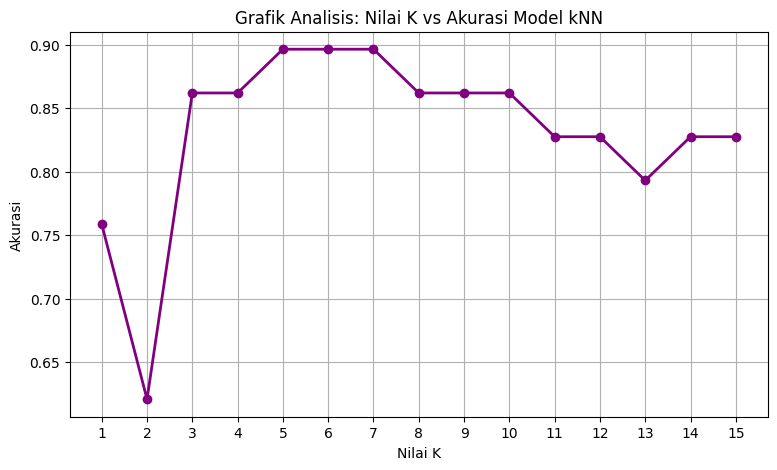

Nilai K Terbaik adalah: 5 dengan Akurasi maksimum: 0.8966


In [6]:
# 3. Evaluasi Nilai K Terbaik menggunakan fitur optimal
X_optimal = data[best_features]
X_tr, X_te, y_tr, y_te = train_test_split(X_optimal, y, test_size=0.3, random_state=42)

sc = StandardScaler()
X_tr_sc = sc.fit_transform(X_tr)
X_te_sc = sc.transform(X_te)

accuracies = []
k_range = range(1, 16)

for k in k_range:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_tr_sc, y_tr)
    preds = knn_k.predict(X_te_sc)
    accuracies.append(accuracy_score(y_te, preds))

# Visualisasi Grafik Analisis Nilai K vs Akurasi
plt.figure(figsize=(9, 5))
plt.plot(k_range, accuracies, marker='o', linestyle='-', color='purple', linewidth=2)
plt.title('Grafik Analisis: Nilai K vs Akurasi Model kNN')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# Menampilkan nilai K dengan akurasi tertinggi
best_k = k_range[np.argmax(accuracies)]
print(f"Nilai K Terbaik adalah: {best_k} dengan Akurasi maksimum: {max(accuracies):.4f}")

Kesimpulan dari analisis model k-Nearest Neighbors (kNN) pada data kafe adalah bahwa nilai $K = 5$ merupakan titik optimal terbaik dengan akurasi tertinggi sekitar $89.66\%$. Penggunaan $K$ yang terlalu kecil berisiko overfitting, sementara $K$ yang terlalu besar menyebabkan underfitting; sehingga $K = 5$ memberikan keseimbangan paling ideal antara fleksibilitas model dan kemampuan generalisasi data.